# 10 - Naive Bayes

**Project:** DetectIt – Intelligent Web Threat Detection Using Machine Learning

**Goal:** Train and evaluate a Gaussian Naive Bayes model on the processed PhiUSIIL data, compare different feature sets, test the URL-only version on the external dataset, choose a better cut-off, and find out which features the model relies on.

**Input:** `data/processed/`

**Output:** `results/metrics/`, `results/confusion_matrices/`, `results/feature_importance/`

## Setup

We load the libraries and the shared functions from `src/`. Every team member uses the same functions, so all results are calculated in the same way and can be compared fairly.

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.metrics import precision_recall_curve, roc_auc_score
from sklearn.model_selection import GridSearchCV, cross_val_predict
from sklearn.naive_bayes import GaussianNB

sys.path.append(str(Path("..").resolve()))
from src.data import PROCESSED_DIR, get_feature_sets, load_feature_groups, load_train_test, load_url_experiment, sample_rows
from src.evaluation import (
    RANDOM_STATE,
    cross_validate_model,
    evaluate_model,
    evaluate_predictions,
    get_scores,
    make_cv,
    make_scaled_pipeline,
    plot_confusion_matrix,
    save_results,
    to_file_name,
)

In [2]:
X_train, X_test, y_train, y_test = load_train_test()
feature_sets = get_feature_sets()

print(f"Training set: {X_train.shape[0]:,} rows | {X_train.shape[1]} features")
print(f"Test set:     {X_test.shape[0]:,} rows | {X_test.shape[1]} features")

Training set: 188,296 rows | 69 features
Test set:     47,074 rows | 69 features


## Model Settings

Gaussian Naive Bayes uses Bayes' theorem. For each URL, it asks: "Given these feature values, is phishing or legitimate more likely?" To keep the maths simple, it makes two assumptions:

1. **Every feature follows a bell curve (normal distribution)** inside each class.
2. **The features are independent** of each other once we know the class. This is the "naive" part.

Our EDA found that 26 of the 31 continuous features are highly skewed, so we use `make_scaled_pipeline`. It applies a log transform (`log1p`), which makes skewed features closer to a bell curve, and then scales them. Both steps are fitted only on the training data, inside the pipeline.

Naive Bayes has only one setting to tune: `var_smoothing`. It adds a small amount to the variance of every feature, so that a feature with almost no spread cannot dominate the prediction. We try values from 10⁻¹² to 10⁻².

Naive Bayes trains in seconds, so we use the full training set for tuning (`TUNING_SAMPLE_SIZE = None`).

In [3]:
MODEL_NAME = "Naive Bayes"
model = make_scaled_pipeline(GaussianNB())

param_grid = {
    "gaussiannb__var_smoothing": np.logspace(-12, -2, 6),
}

TUNING_SAMPLE_SIZE = None

## 1. Hyperparameter Tuning

We try each value in `param_grid` using 3-fold cross-validation on the training set, and keep the one with the best F1-score. The test set is not used here.

In [4]:
X_tune, y_tune = sample_rows(X_train, y_train, TUNING_SAMPLE_SIZE)

search = GridSearchCV(model, param_grid, scoring="f1", cv=make_cv(3), n_jobs=-1)
search.fit(X_tune, y_tune)
best_model = search.best_estimator_

print(f"Best settings: {search.best_params_}")
print(f"Best cross-validation F1: {search.best_score_:.4f}")

Best settings: {'gaussiannb__var_smoothing': np.float64(1e-12)}
Best cross-validation F1: 0.9996


In [5]:
tuning_table = pd.DataFrame({
    "var_smoothing": [f"{v:.0e}" for v in search.cv_results_["param_gaussiannb__var_smoothing"]],
    "Mean F1": search.cv_results_["mean_test_score"],
    "Std": search.cv_results_["std_test_score"],
})
tuning_table.round(4)

,var_smoothing,Mean F1,Std
0,1e-12,0.9996,0.0001
1,1e-10,0.9995,0.0000
2,1e-08,0.9994,0.0001
3,1e-06,0.9993,0.0001
4,1e-04,0.9992,0.0001
5,1e-02,0.9988,0.0001


## 2. Cross-Validation

We check the best model with 5-fold stratified cross-validation. The mean shows the usual score, and the standard deviation (Std) shows how stable the model is. A small Std means the model gives similar results on different parts of the data.

In [6]:
cv_results = cross_validate_model(best_model, X_tune, y_tune)
cv_results.round(4)

,Mean,Std
Accuracy,0.9997,0.0001
Precision,0.9994,0.0002
Recall,0.9999,0.0001
F1,0.9996,0.0001
ROC-AUC,0.9999,0.0001


## 3. Final Test

We train the best model on the full training set and test it once on the test set. This is the score we report for this model.

In [7]:
start = time.perf_counter()
final_model = clone(best_model).fit(X_train, y_train)
train_time = time.perf_counter() - start

test_results = evaluate_model(final_model, X_test, y_test)
print(f"Training time: {train_time:.1f} seconds")
pd.Series(test_results).round(4).to_frame("Test Score")

Training time: 0.5 seconds


,Test Score
Accuracy,0.9997
Precision,0.9995
Recall,1.0000
F1,0.9997
ROC-AUC,0.9999


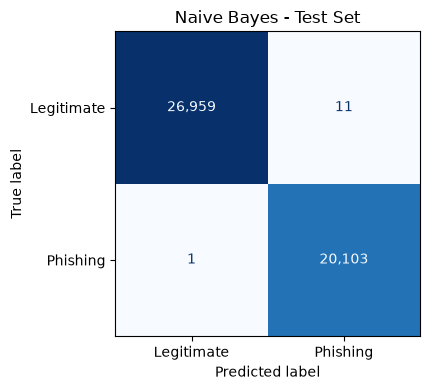

In [8]:
test_pred = final_model.predict(X_test)
plot_confusion_matrix(y_test, test_pred, f"{MODEL_NAME} - Test Set")

## 4. Feature Set Comparison

We train the same model on two smaller feature sets to answer two questions:

- **Original features only:** do our new features from feature engineering improve the model?
- **Without `URLSimilarityIndex`:** does the model still work well without its strongest feature?

In [9]:
feature_results = {"All features": test_results}

for set_name in ["Original features only", "Without URLSimilarityIndex"]:
    features = feature_sets[set_name]
    set_model = clone(best_model).fit(X_train[features], y_train)
    feature_results[set_name] = evaluate_model(set_model, X_test[features], y_test)

pd.DataFrame(feature_results).T.round(4)

,Accuracy,Precision,Recall,F1,ROC-AUC
All features,0.9997,0.9995,1.0000,0.9997,0.9999
Original features only,0.9995,0.9989,0.9999,0.9994,0.9996
Without URLSimilarityIndex,0.9953,0.9993,0.9897,0.9945,0.9998


## 5. Experiment 2: URL Features Only

Here the model only uses the 18 URL features that we can create from any URL. We train it on PhiUSIIL and test it on both the PhiUSIIL test set and the external dataset. The difference between the two scores shows how well the model works on data from a different source.

In [10]:
X_url_train, X_url_test, X_external, y_url_train, y_url_test, y_external = load_url_experiment()

url_model = clone(best_model).fit(X_url_train, y_url_train)
url_results = {
    "PhiUSIIL test set": evaluate_model(url_model, X_url_test, y_url_test),
    "External dataset": evaluate_model(url_model, X_external, y_external),
}
pd.DataFrame(url_results).T.round(4)

,Accuracy,Precision,Recall,F1,ROC-AUC
PhiUSIIL test set,0.9927,0.9999,0.9830,0.9914,0.9976
External dataset,0.5018,0.5026,0.9913,0.6670,0.4986


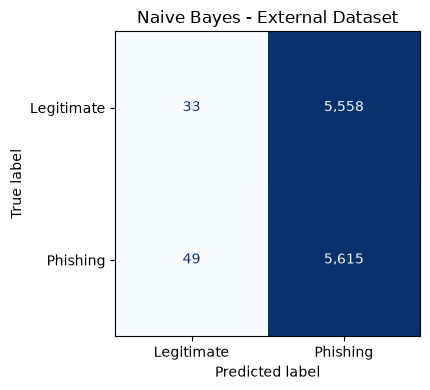

In [11]:
plot_confusion_matrix(y_external, url_model.predict(X_external), f"{MODEL_NAME} - External Dataset")

## 6. Choosing the Cut-off

By default, a URL is called phishing when the model gives it a probability of 0.5 or more. But the two mistakes do not cost the same: **a missed phishing URL can steal a user's password, while a false alarm only blocks a safe page**. So we choose the cut-off based on the cost of errors.

Our rule: **find at least 95% of phishing URLs (recall ≥ 0.95), and among the cut-offs that do this, pick the one with the fewest false alarms (highest precision).**

To choose the cut-off without touching the test set, we use *out-of-fold* predictions: with 5-fold cross-validation, every training URL gets a probability from a model that did not see it during training. We then apply the chosen cut-off to the test set once.

This step is especially useful for Naive Bayes, because its independence assumption pushes most probabilities very close to 0 or 1, so 0.5 is not always a good place to cut.

In [12]:
oof_proba = cross_val_predict(best_model, X_train, y_train, cv=make_cv(5), method="predict_proba", n_jobs=-1)[:, 1]
precision, recall, thresholds = precision_recall_curve(y_train, oof_proba)

TARGET_RECALL = 0.95
meets_target = recall[:-1] >= TARGET_RECALL
best_threshold = thresholds[meets_target][np.argmax(precision[:-1][meets_target])]
print(f"Chosen cut-off: {best_threshold:.4f}")

Chosen cut-off: 1.0000


In [13]:
test_proba = final_model.predict_proba(X_test)[:, 1]
tuned_pred = (test_proba >= best_threshold).astype(int)
tuned_results = evaluate_predictions(y_test, tuned_pred, test_proba)

pd.DataFrame({
    "Cut-off 0.5": test_results,
    f"Cut-off {best_threshold:.4f}": tuned_results,
}).round(4)

,Cut-off 0.5,Cut-off 1.0000
Accuracy,0.9997,0.9998
Precision,0.9995,0.9996
Recall,1.0000,1.0000
F1,0.9997,0.9998
ROC-AUC,0.9999,0.9999


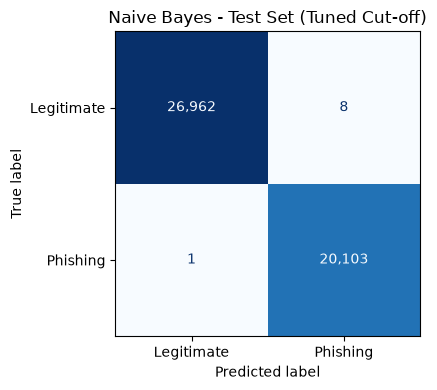

In [14]:
plot_confusion_matrix(y_test, tuned_pred, f"{MODEL_NAME} - Test Set (Tuned Cut-off)")

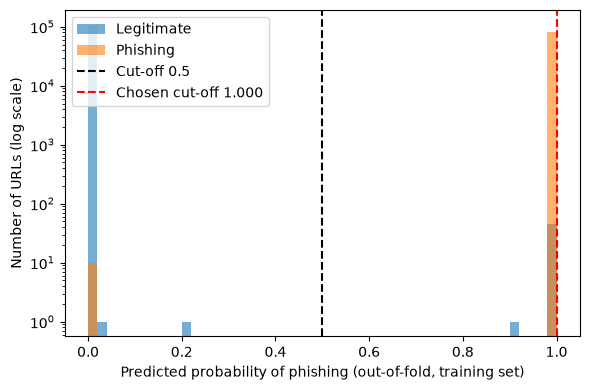

In [15]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(oof_proba[y_train == 0], bins=50, alpha=0.6, label="Legitimate", log=True)
ax.hist(oof_proba[y_train == 1], bins=50, alpha=0.6, label="Phishing", log=True)
ax.axvline(0.5, color="black", linestyle="--", label="Cut-off 0.5")
ax.axvline(best_threshold, color="red", linestyle="--", label=f"Chosen cut-off {best_threshold:.3f}")
ax.set_xlabel("Predicted probability of phishing (out-of-fold, training set)")
ax.set_ylabel("Number of URLs (log scale)")
ax.legend()
fig.tight_layout()
plt.show()

**What this shows:** Naive Bayes is extremely over-confident. Almost every phishing URL in the training set (99.99%) gets a probability of exactly 1.0, so the histogram has almost nothing in the middle. Because of this, the rule picks a cut-off of 1.0, which means "only call a URL phishing when the model is completely sure". On the test set this removes 3 false alarms (11 → 8) and misses no extra phishing URLs (still 1). That is 3 URLs out of 47,074, which is too small to be a meaningful difference, and a cut-off of exactly 1.0 is fragile. So we keep **0.5 as the main result** for this model and report the tuned cut-off only as an extra.

## 7. Prediction Speed

A phishing detector must be fast, because it checks every link a user opens. We measure how long the model takes to classify all test URLs.

In [16]:
start = time.perf_counter()
final_model.predict(X_test)
predict_time = time.perf_counter() - start

print(f"Training time:   {train_time:.2f} seconds")
print(f"Prediction time: {predict_time:.3f} seconds for {len(X_test):,} URLs "
      f"({predict_time / len(X_test) * 1e6:.1f} microseconds per URL)")

Training time:   0.48 seconds
Prediction time: 0.085 seconds for 47,074 URLs (1.8 microseconds per URL)


## 8. Which Features Does the Model Rely On?

Naive Bayes does not give feature importances directly, so we use **permutation importance**: we shuffle one feature at a time on the test set and see how much ROC-AUC drops. If the score drops a lot, the model was relying on that feature. We use a sample of 10,000 test URLs and repeat each shuffle 3 times.

Many of our features are correlated, so shuffling one feature can look harmless because a "twin" feature still carries the same information. To handle this, we also shuffle **whole groups** of features at once.

In [17]:
get_score = get_scores

def permutation_auc_drop(model, X, y, groups, repeats=3):
    """Shuffle each group of columns together and measure how much ROC-AUC drops."""
    rng = np.random.default_rng(RANDOM_STATE)
    base = roc_auc_score(y, get_score(model, X))
    rows = {}
    for name, cols in groups.items():
        drops = []
        for _ in range(repeats):
            X_shuffled = X.copy()
            X_shuffled[cols] = X_shuffled[cols].values[rng.permutation(len(X_shuffled))]
            drops.append(base - roc_auc_score(y, get_score(model, X_shuffled)))
        rows[name] = {"AUC drop": np.mean(drops), "Std": np.std(drops)}
    return pd.DataFrame(rows).T.sort_values("AUC drop", ascending=False)

X_imp, y_imp = sample_rows(X_test, y_test, 10000)

start = time.perf_counter()
single_importance = permutation_auc_drop(final_model, X_imp, y_imp, {col: [col] for col in X_imp.columns})
print(f"Done in {time.perf_counter() - start:.0f} seconds")
single_importance.head(15).round(4)

Done in 5 seconds


,AUC drop,Std
URLSimilarityIndex,0.2133,0.0021
NoOfSlashesInURL,0.1295,0.0013
PathLength,0.1283,0.0017
IsHTTPS,0.1070,0.0020
PathDepth,0.0584,0.0012
QueryLength,0.0141,0.0006
NoOfQMarkInURL,0.0134,0.0009
HasTitle,0.0123,0.0009
NoOfEqualsInURL,0.0113,0.0009
HasAtSymbol,0.0032,0.0003


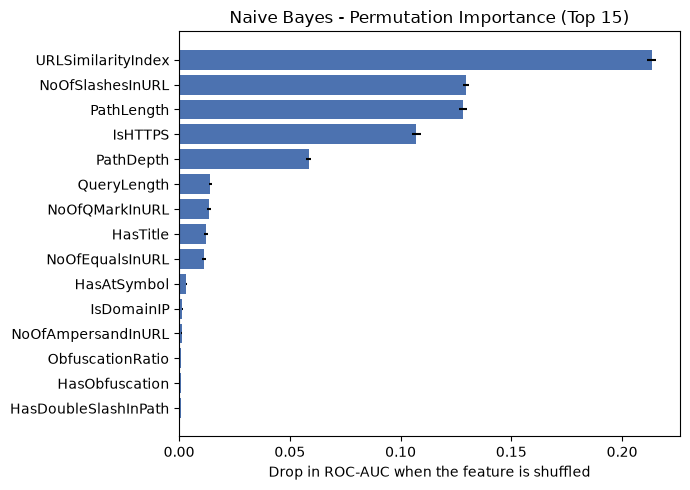

In [18]:
save_dir = Path("../results/feature_importance")
save_dir.mkdir(parents=True, exist_ok=True)

top = single_importance.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(top.index, top["AUC drop"], xerr=top["Std"], color="#4C72B0")
ax.set_xlabel("Drop in ROC-AUC when the feature is shuffled")
ax.set_title(f"{MODEL_NAME} - Permutation Importance (Top 15)")
fig.tight_layout()
fig.savefig(save_dir / f"{to_file_name(MODEL_NAME)}.png", dpi=300)
plt.show()

In [19]:
groups = load_feature_groups()
group_importance = permutation_auc_drop(final_model, X_imp, y_imp, {
    "URLSimilarityIndex": ["URLSimilarityIndex"],
    "Other original features (47)": [col for col in groups["original"] if col != "URLSimilarityIndex"],
    "Engineered features (21)": groups["engineered"],
})
group_importance.round(4)

,AUC drop,Std
URLSimilarityIndex,0.2154,0.0024
Other original features (47),0.1466,0.0015
Engineered features (21),0.1293,0.0005


## 9. Where Does the Model Go Wrong?

A score tells us how often the model is wrong, but not why. Here we look at the URLs the model got wrong at the default cut-off (0.5).

In [20]:
test_urls = pd.read_csv(PROCESSED_DIR / "test_urls.csv")["URL"].values
errors = pd.DataFrame({"URL": test_urls, "Actual": y_test.values, "Predicted": test_pred})

missed = errors[(errors["Actual"] == 1) & (errors["Predicted"] == 0)]
false_alarms = errors[(errors["Actual"] == 0) & (errors["Predicted"] == 1)]
print(f"Missed phishing URLs (false negatives): {len(missed):,}")
print(f"False alarms (false positives):         {len(false_alarms):,}")

Missed phishing URLs (false negatives): 1
False alarms (false positives):         11


In [21]:
print("Examples of missed phishing URLs:")
display(missed.sample(min(10, len(missed)), random_state=RANDOM_STATE)[["URL"]])
print("Examples of false alarms:")
display(false_alarms.sample(min(10, len(false_alarms)), random_state=RANDOM_STATE)[["URL"]])

Examples of missed phishing URLs:


,URL
10455,https://www.opallegal.com.au


Examples of false alarms:


,URL
21249,https://www.ssca.org.in
8951,https://www.bookunitsteacher.com
38526,https://www.britisharmedforces.org
45028,https://www.vocaleapp.com
13907,https://www.ifotes.org
11086,https://www.counterpointpress.com
36640,https://www.nathanselikoff.com
18779,https://www.talktalkgroup.com
28742,https://www.n-svirsky.ru
17519,https://www.ibby.org


In [22]:
def url_shape(urls):
    urls = pd.Series(urls)
    return pd.Series({
        "Avg URL length": urls.str.len().mean(),
        "Has a path (%)": urls.str.replace(r"^https?://", "", regex=True).str.contains("/.", regex=True).mean() * 100,
        "Uses HTTPS (%)": urls.str.startswith("https").mean() * 100,
    })

pd.DataFrame({
    "All phishing": url_shape(errors.loc[errors["Actual"] == 1, "URL"]),
    "Missed phishing": url_shape(missed["URL"]),
    "All legitimate": url_shape(errors.loc[errors["Actual"] == 0, "URL"]),
    "False alarms": url_shape(false_alarms["URL"]),
}).round(1)

,All phishing,Missed phishing,All legitimate,False alarms
Avg URL length,45.6,28.0,27.2,27.3
Has a path (%),28.5,0.0,0.0,0.0
Uses HTTPS (%),48.8,100.0,100.0,100.0


## 10. Save the Results

We save all results in one table. The comparison notebook will later load the tables of all models.

In [23]:
results = [
    {"Experiment": "Cross-validation", **cv_results["Mean"].to_dict()},
    {"Experiment": "Test set - All features", **test_results, "Train Time (s)": train_time, "Predict Time (s)": predict_time},
    {"Experiment": f"Test set - Tuned cut-off ({best_threshold:.4f})", **tuned_results},
    {"Experiment": "Test set - Original features only", **feature_results["Original features only"]},
    {"Experiment": "Test set - Without URLSimilarityIndex", **feature_results["Without URLSimilarityIndex"]},
    {"Experiment": "URL features - PhiUSIIL test set", **url_results["PhiUSIIL test set"]},
    {"Experiment": "URL features - External dataset", **url_results["External dataset"]},
]

save_results(MODEL_NAME, results).round(4)

,Model,Experiment,Accuracy,Precision,Recall,F1,ROC-AUC,Train Time (s),Predict Time (s)
0,Naive Bayes,Cross-validation,0.9997,0.9994,0.9999,0.9996,0.9999,NaN,NaN
1,Naive Bayes,Test set - All features,0.9997,0.9995,1.0000,0.9997,0.9999,0.4819,0.085
2,Naive Bayes,Test set - Tuned cut-off (1.0000),0.9998,0.9996,1.0000,0.9998,0.9999,NaN,NaN
3,Naive Bayes,Test set - Original features only,0.9995,0.9989,0.9999,0.9994,0.9996,NaN,NaN
4,Naive Bayes,Test set - Without URLSimilarityIndex,0.9953,0.9993,0.9897,0.9945,0.9998,NaN,NaN
5,Naive Bayes,URL features - PhiUSIIL test set,0.9927,0.9999,0.9830,0.9914,0.9976,NaN,NaN
6,Naive Bayes,URL features - External dataset,0.5018,0.5026,0.9913,0.6670,0.4986,NaN,NaN


## 11. Findings

**1. Very high scores on the PhiUSIIL test set.** Naive Bayes reaches 99.97% accuracy, an F1-score of 0.9997 and a ROC-AUC of 0.9999. It missed only **1 of 20,104** phishing URLs and wrongly flagged **11 of 26,970** legitimate URLs. The cross-validation F1 (0.9996 ± 0.0001) is almost the same as the test F1, so the cross-validation estimate was honest and the model is not overfitting.

**2. Tuning barely mattered.** All `var_smoothing` values gave an F1 between 0.9988 and 0.9996. The smallest value (10⁻¹²) was best, but the differences are tiny.

**3. Very fast.** Training took about 0.5 seconds and predicting 47,074 URLs about 0.09 seconds (about 2 microseconds per URL). This makes Naive Bayes a good choice for real-time checking. (Times depend on the computer used.)

**4. The new features helped only a little.** With original features only, F1 was 0.9994. With our engineered features, it was 0.9997. The gap is too small to claim a meaningful improvement.

**5. `URLSimilarityIndex` matters most, but the model still works without it.** Without this feature, recall drops from 1.000 to 0.990 (about 200 more phishing URLs missed), while precision stays at 0.999. ROC-AUC is still 0.9998, so the model still *ranks* URLs well, but the 0.5 cut-off no longer fits as well. Permutation importance agrees: shuffling `URLSimilarityIndex` lowers ROC-AUC by 0.21, followed by `NoOfSlashesInURL` (0.13), `PathLength` (0.13), `IsHTTPS` (0.11) and `PathDepth` (0.06). These show which features the model *relies on*, not what *causes* a URL to be phishing.

**6. The mistakes reveal how the dataset was built.** In the PhiUSIIL test set, **every legitimate URL is a plain HTTPS home page** (0% have a path, 100% use HTTPS), while 28.5% of phishing URLs have a path and only 48.8% use HTTPS. The 1 missed phishing URL and all 11 false alarms are plain HTTPS home pages, so the model only fails where a phishing URL looks exactly like a typical legitimate URL in this dataset.

**7. The URL-only model fails on the external dataset.** On the PhiUSIIL test set, the URL-only model still scores an F1 of 0.991. On the external dataset, accuracy falls to **50.2%** and ROC-AUC to **0.499**, which is no better than guessing. Recall is 0.99 but precision is only 0.50, so the model calls almost every external URL phishing. This is because legitimate URLs in the external dataset often have paths and do not use HTTPS, and the model learned these as signs of phishing (see the `03_external_dataset` notebook). **This is the most important finding: the near-perfect PhiUSIIL scores mostly reflect how this dataset was collected, not how well the model would work in the real world.**

**8. Choosing a cut-off did not change the result.** Naive Bayes gives almost every phishing URL a probability of exactly 1.0. The tuned cut-off (1.0) removed 3 false alarms, which is not a meaningful difference, so we report the 0.5 cut-off as the main result.

**Limitation:** Naive Bayes assumes that features are independent, but many of our features are correlated (for example, `NoOfSlashesInURL`, `PathLength` and `PathDepth` all describe the URL path). This is the reason for its over-confident probabilities. It still works well here because a few features separate the classes so clearly.

**Next step:** Train on more varied legitimate URLs (inner pages and non-HTTPS sites), so the model does not learn "has a path" or "no HTTPS" as a sign of phishing.